# Zadanie 1

## 1.0 Importowanie datasetu

In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
iris = fetch_ucirepo(id=53)

# data (as pandas dataframes)
X = iris.data.features
y = iris.data.targets

display(X.head(3))
display(y.head(3))

,sepal length,sepal width,petal length,petal width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


,class
0,Iris-setosa
1,Iris-setosa
2,Iris-setosa


## 1.1
Jakie wartości przyjmuje sepal length? Zrób wykres (typu scatter plot): na osi X numer
próbki danych, na osi Y wartość sepal length. Czy jest sens łączyć kropki na tym wykresie?

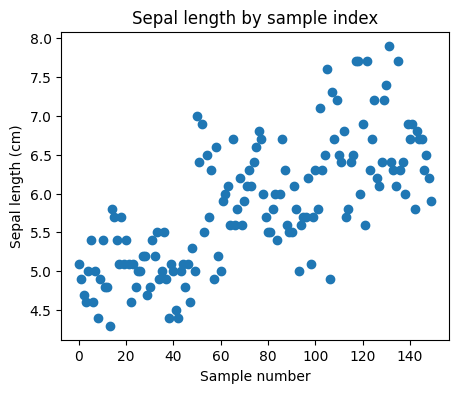

In [ ]:
from matplotlib import pyplot as plt

plt.figure(figsize=(5, 4))
plt.scatter(range(len(X)), X['sepal length'])
plt.xlabel("Sample number")
plt.ylabel("Sepal length (cm)")
plt.title("Sepal length by sample index")
plt.show()

## 1.2

Sprawdź ile jest próbek danych klasy iris setosa, dla których sepal width jest mniejszy niż
2.5. A między 2.5 i 3.0? A między 3.0 i 3.5? Itd. Zrób odpowiedni wykres (typu słupkowego).
Czy zrobiłeś histogram?

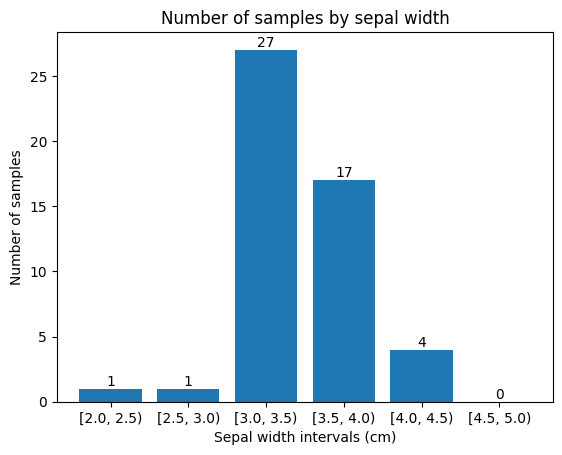

In [ ]:
import pandas as pd
import numpy as np

df = X.join(y)
data = df[df['class'] == 'Iris-setosa']

bins = np.arange(2, 5.5, 0.5) # max sepal width ~ 4.5

bins_count = pd.cut(
    data['sepal width'],
    bins,
    right=False
).value_counts().sort_index()


plt.xlabel("Sepal width intervals (cm)")
plt.ylabel("Number of samples")
plt.title("Number of samples by sepal width")
bars = plt.bar(bins_count.index.astype(str), bins_count.values)
plt.bar_label(bars)
plt.show()


## 1.3
Zrób wykres (typu scatter plot): na osi X sepal length, na osi Y sepal width. Czy jest
sens łączyć kropki na tym wykresie? Pokoloruj kropki trzema różnymi kolorami w zależności
od gatunku irysa. Ustaw rozmiar kropek proporcjonalnie do petal length (skalę rozmiarów
dobierz tak, aby rysunek był czytelny). Co ciekawego widać na tym wykresie? Czy potrafisz
wykorzystać wykres, żeby podać regułę odróżniania iris setosa od pozostałych dwóch gatunków
irysa?

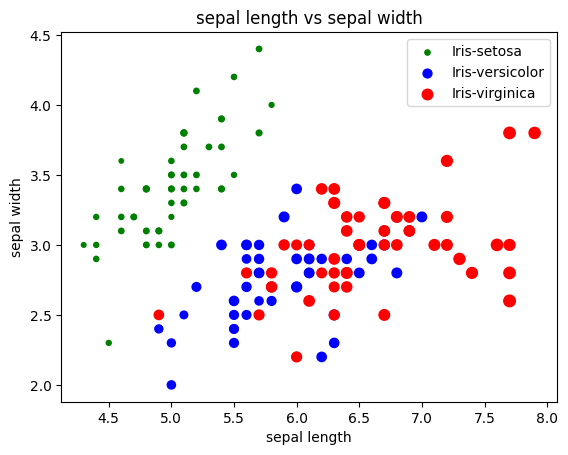

In [ ]:

species = df['class'].unique()
colors = ['green', 'blue', 'red']

def scatter_plot(a, b, ax=None):
    """Scatter plot for two attributes"""

    if ax is None:
        fig, ax = plt.subplots()

    for group, color in zip(species, colors):
        limited_df = df[df['class'] == group] # limit df to a single specie

        ax.scatter(limited_df[a], limited_df[b], s=limited_df['petal length'] * 10, c=color, label=group)

    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}")
    ax.legend()

scatter_plot('sepal length', 'sepal width')

Klasa 'iris-setosa' wyraźnie się odróżnia. Można oddzielić ją prostą od pozostałych dwóch.

## 1.4
Zrób wykres z poprzedniego punktu dla każdej pary różnych atrybutów danych. Przemyśl, czy
nie będzie wygodnie ustawić wykresy w jakiś sposób obok siebie, a nie jeden pod drugim.

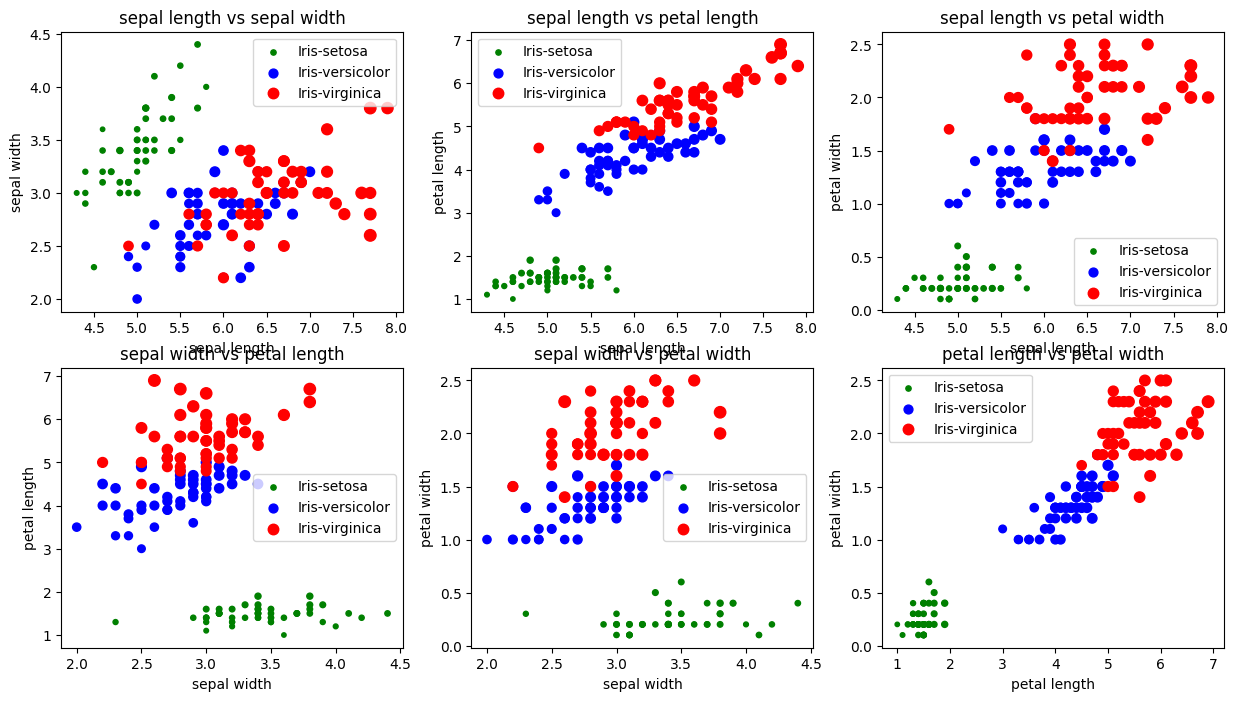

In [ ]:
from itertools import combinations

features = [col for col in df.columns if col != 'class']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, (a, b) in zip(axes.flat, combinations(features, 2)):
    scatter_plot(a, b, ax)

## 1.5
Dowiedz się czym jest wykres skrzypcowy (ang. violin plot) i zrób go dla atrybutów danych.


# Zadanie 2


## 2.0
Znajdź i pobierz zbiór danych BANK MARKETING z repozytorium danych UCI. Dowiedz
się co opisują pobrane dane.

In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
bank_marketing = fetch_ucirepo(id=222)

# data (as pandas dataframes)
X = bank_marketing.data.features
y = bank_marketing.data.targets

# # metadata
# print(bank_marketing.metadata)

# # variable information
# print(bank_marketing.variables)


## 2.1

Zrób histogram atrybutu duration dla całości danych. Następnie zrób analogiczne dwa histo-
gramy, osobno dla próbek pozytywnych i negatywnych (atrybut y równy yes albo no, odpo-
wiednio). Co ciekawego widać na tych wykresach?

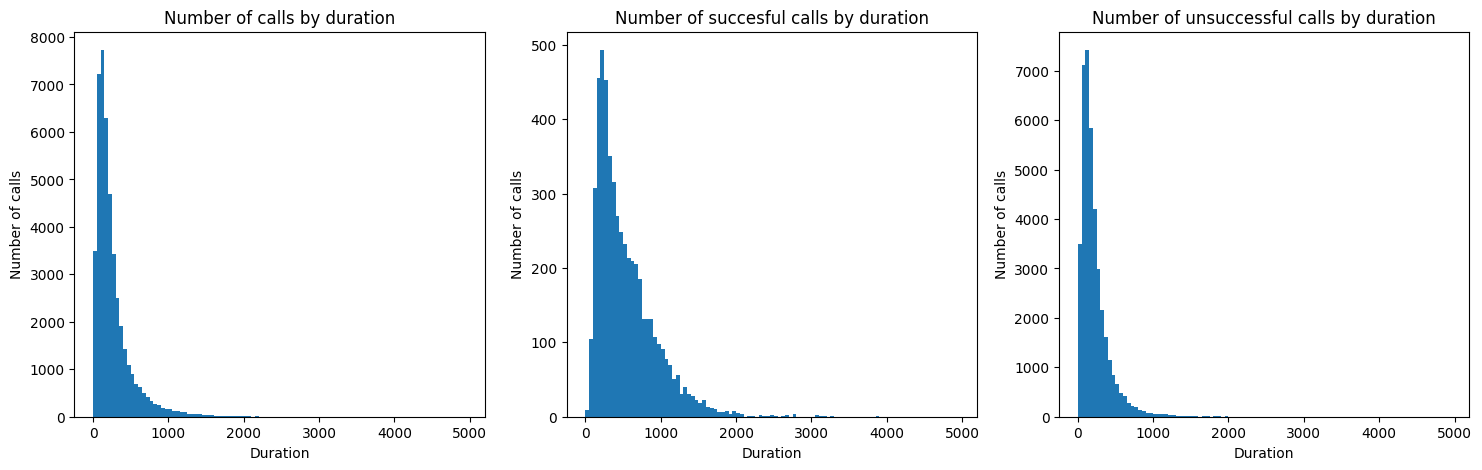

In [ ]:
from matplotlib import pyplot as plt
import numpy as np

df = X.join(y)
fig, axes = plt.subplots(1, 3, figsize=(18,5))

bins = np.arange(0, int(max(df['duration'])) + 50, 50)

axes[0].hist(df['duration'], bins=bins)
axes[0].set_xlabel("Duration")
axes[0].set_ylabel("Number of calls")
axes[0].set_title("Number of calls by duration")

axes[1].hist(df[df['y'] == 'yes']['duration'], bins=bins) # first filter, then select the column
axes[1].set_xlabel("Duration")
axes[1].set_ylabel("Number of calls")
axes[1].set_title("Number of succesful calls by duration")

axes[2].hist(df[df['y'] == 'no']['duration'], bins=bins)
axes[2].set_xlabel("Duration")
axes[2].set_ylabel("Number of calls")
axes[2].set_title("Number of unsuccessful calls by duration")

fig.show()

## 2.2
Zrób histogram atrybutu balance dla osób powyżej 25 roku życia (atrybut age większy niż 25).
Zapoznaj się z pakietem ipywidgets, a następnie przekształć swój wykres w interaktywny z
suwakiem do wybierania granicy wieku i zobacz jak zmienia się histogram.

In [ ]:

def histogram(age_limit, bin_width):
    bins = np.arange(0, int(max(df['balance'])) + 500, bin_width)

    plt.hist(df[df['age'] > age_limit]['balance'], bins=bins)
    plt.xlabel("Balance")
    plt.ylabel("Number of samples")
    plt.title(f"Number of samples by balance and age limit > {age_limit}")
    plt.show()


from ipywidgets import interact
import ipywidgets as widgets

interact(
    histogram,
    age_limit=widgets.IntSlider(min=0, max=100, step=1, value=25),
    bin_width=widgets.IntSlider(min=100, max=10000, step=100, value=500)
)



interactive(children=(IntSlider(value=25, description='age_limit'), IntSlider(value=500, description='bin_widt…

<function __main__.histogram(age_limit, bin_width)>

## 2.3
Dla ustalonego progu, t = 360, czasu trwania rozmowy (atrybut duration), wyznacz próbki
danych z atrybutem duration powyżej progu t. Policz ile procent z nich to próbki pozytywne.
Powtórz obliczenia dla różnych t i zrób wykres: na osi X próg t, na osi Y procent próbek
pozytywnych. Spróbuj wytłumaczyć zjawisko widoczne na wykresie.

33.0%


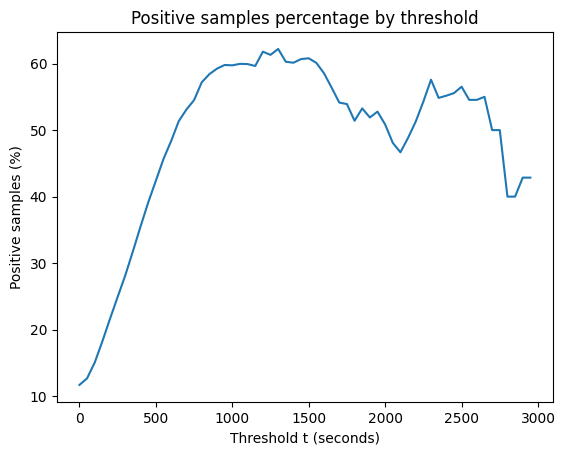

In [ ]:
t = 360

all_samples = df[df['duration'] > t]

positive_samples = all_samples['y'] == 'yes'

print(f"{round(positive_samples.sum()/len(all_samples), 2) * 100}%")


thresholds = np.arange(0, 3000, 50)
percentages = []


for t in thresholds:
    samples = df[df['duration'] > t]

    positive_samples = samples[samples['y'] == 'yes']

    percentage = len(positive_samples) / len(samples) * 100
    percentages.append(percentage)

plt.plot(thresholds, percentages)
plt.xlabel('Threshold t (seconds)')
plt.ylabel('Positive samples (%)')
plt.title('Positive samples percentage by threshold')
plt.show()

Im dłuższa rozmowa tym większy odsetek pozytywnych odpowiedzi.

## 2.4
Powtórz poprzedni punkt dla atrybutu balance. Wyobraź sobie, że przeprowadzasz kampanię
marketingową lokat bankowych. Możesz kontaktować się z losowo wybranymi (z rozkładem
jednostajnym na całych danych) klientami banku, albo jedynie z klientami o saldzie (atrybut
balance) powyżej ustalonego progu (możesz sam ustalić ten próg). Która strategia jest lepsza?
Jaki próg wybrać?

t = 0: 12.62% pozytywnych, klienci: 37931, potencjalne sukcesy: 4787
t = 500: 14.42% pozytywnych, klienci: 21546, potencjalne sukcesy: 3107
t = 1000: 15.36% pozytywnych, klienci: 14631, potencjalne sukcesy: 2248
t = 1500: 16.32% pozytywnych, klienci: 10895, potencjalne sukcesy: 1778
t = 2000: 16.57% pozytywnych, klienci: 8501, potencjalne sukcesy: 1409
t = 2500: 16.79% pozytywnych, klienci: 6875, potencjalne sukcesy: 1154
t = 3000: 16.34% pozytywnych, klienci: 5611, potencjalne sukcesy: 917
t = 3500: 16.15% pozytywnych, klienci: 4649, potencjalne sukcesy: 751
t = 4000: 15.85% pozytywnych, klienci: 3898, potencjalne sukcesy: 618
t = 4500: 15.64% pozytywnych, klienci: 3351, potencjalne sukcesy: 524
t = 5000: 15.50% pozytywnych, klienci: 2845, potencjalne sukcesy: 441
t = 5500: 15.01% pozytywnych, klienci: 2438, potencjalne sukcesy: 366
t = 6000: 15.13% pozytywnych, klienci: 2108, potencjalne sukcesy: 319
t = 6500: 15.73% pozytywnych, klienci: 1850, potencjalne sukcesy: 291
t = 7000: 15.7

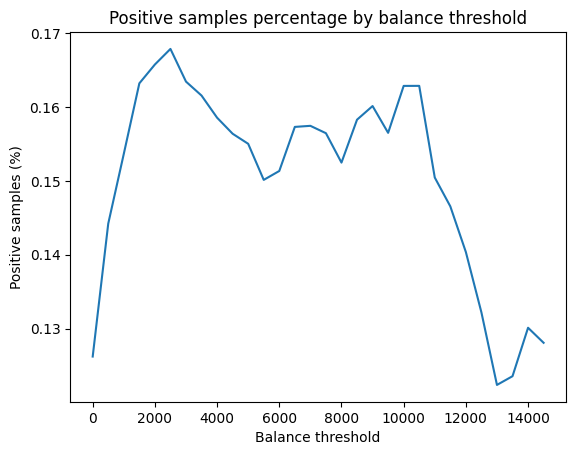

In [ ]:
thresholds = np.arange(0, 15000, 500)
percentages = []

for t in thresholds:
    samples = df[df['balance'] > t]
    positive_samples = samples[samples['y'] == 'yes']

    percentage = len(positive_samples) / len(samples)
    customers = len(samples)

    print(f"t = {t}: {percentage * 100:.2f}% pozytywnych, klienci: {customers}, potencjalne sukcesy: {round(percentage * customers)}")
    percentages.append(percentage)

plt.plot(thresholds, percentages)
plt.xlabel('Balance threshold')
plt.ylabel('Positive samples (%)')
plt.title('Positive samples percentage by balance threshold')
plt.show()

Wybierając próg salda na poziomie 2500, osiągamy najwyższy odsetek pozytywnych odpowiedzi. Jednocześnie liczba potencjalnych sukcesów jest mniejsza, ponieważ kontaktujemy się z mniejszą liczbą klientów. Strategia ta pozwala jednak efektywniej wykorzystać zasoby, ograniczyć liczbę wykonywanych telefonów i zwiększyć skuteczność pojedynczej rozmowy.

## 2.5

Podziel losowo zbiór danych na dwie części porównywalnej wielkości. Używając pierwszej części
danych, zrób wykres opisany w pkt. 4 i ustal próg (według własnego pomysłu). Przyjmij,
że klienci z saldem powyżej ustalonego progu powinni być zainteresowani lokatą bankową
(powinni być próbkami pozytywnymi). Oblicz ilu z nich, procentowo, nie było. Oblicz też
ilu zainteresowanych lokatą klientów miało saldo nie większe od ustalonego progu. Następnie
policz takie błędy modelu na drugiej części danych. Powtórz obliczenia dla różnych wartości
progów. Zrób wykres (według własnego pomysłu) prezentujący wyniki. Ostatecznie, to jaki
próg wybrać?

t = 0: 12.60% pozytywnych, klienci: 18914, potencjalne sukcesy: 2383
t = 500: 14.19% pozytywnych, klienci: 10771, potencjalne sukcesy: 1528
t = 1000: 14.87% pozytywnych, klienci: 7303, potencjalne sukcesy: 1086
t = 1500: 15.95% pozytywnych, klienci: 5466, potencjalne sukcesy: 872
t = 2000: 16.06% pozytywnych, klienci: 4284, potencjalne sukcesy: 688
t = 2500: 16.18% pozytywnych, klienci: 3461, potencjalne sukcesy: 560
t = 3000: 15.77% pozytywnych, klienci: 2821, potencjalne sukcesy: 445
t = 3500: 15.81% pozytywnych, klienci: 2346, potencjalne sukcesy: 371
t = 4000: 15.36% pozytywnych, klienci: 1966, potencjalne sukcesy: 302
t = 4500: 14.72% pozytywnych, klienci: 1692, potencjalne sukcesy: 249
t = 5000: 14.91% pozytywnych, klienci: 1435, potencjalne sukcesy: 214
t = 5500: 14.34% pozytywnych, klienci: 1227, potencjalne sukcesy: 176
t = 6000: 14.94% pozytywnych, klienci: 1064, potencjalne sukcesy: 159
t = 6500: 15.15% pozytywnych, klienci: 931, potencjalne sukcesy: 141
t = 7000: 15.46% poz

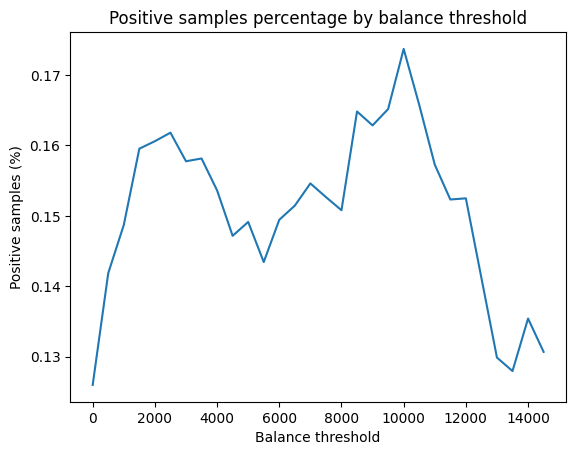

In [ ]:
from sklearn.model_selection import train_test_split

# Train, test datasets
train, test = train_test_split(
    df,
    test_size=0.5,
    random_state=42
)

thresholds = np.arange(0, 15000, 500)
percentages = []

for t in thresholds:
    samples = train[train['balance'] > t]
    positive_samples = samples[samples['y'] == 'yes']

    percentage = len(positive_samples) / len(samples)
    customers = len(samples)

    print(f"t = {t}: {percentage * 100:.2f}% pozytywnych, klienci: {customers}, potencjalne sukcesy: {round(percentage * customers)}")
    percentages.append(percentage)


plt.plot(thresholds, percentages)
plt.xlabel('Balance threshold')
plt.ylabel('Positive samples (%)')
plt.title('Positive samples percentage by balance threshold')
plt.show()


In [ ]:
# Sprawdzamy dla zbioru Train
# Weźmy t = 2500
t = 2500

print(f"Threshold > {t}:")
samples = train[train['balance'] > t]
error_rate = (samples['y'] == 'no').mean() # False positives, model powiedział 'tak', a w rzeczywistości było 'nie'

print(f"Error rate: {round(error_rate, 2) * 100}%\n")

print(f"Threshold <= {t}:")
samples = train[train['balance'] <= t]
positive_samples = (samples['y'] == 'yes').sum() # False negatives, model powiedział 'nie', a w rzeczywistości było 'tak'

print(f"Liczba pozytywnych próbek, które zostały odrzucone: {positive_samples}")

Threshold > 2500:
Error rate: 84.0%

Threshold <= 2500:
Liczba pozytywnych próbek, które zostały odrzucone: 2068


In [ ]:
# Sprawdzamy dla zbioru Test
# Weźmy t = 2500
t = 2500

print(f"Threshold > {t}:")
samples = test[test['balance'] > t]
error_rate = (samples['y'] == 'no').mean() # False positives, model powiedział 'tak', a w rzeczywistości było 'nie'

print(f"Error rate: {round(error_rate, 2) * 100}%\n")

print(f"Threshold <= {t}:")
samples = test[test['balance'] <= t]
positive_samples = (samples['y'] == 'yes').sum()

print(f"Liczba pozytywnych próbek, które zostały odrzucone: {positive_samples}")



Threshold > 2500:
Error rate: 83.0%

Threshold <= 2500:
Liczba pozytywnych próbek, które zostały odrzucone: 2067


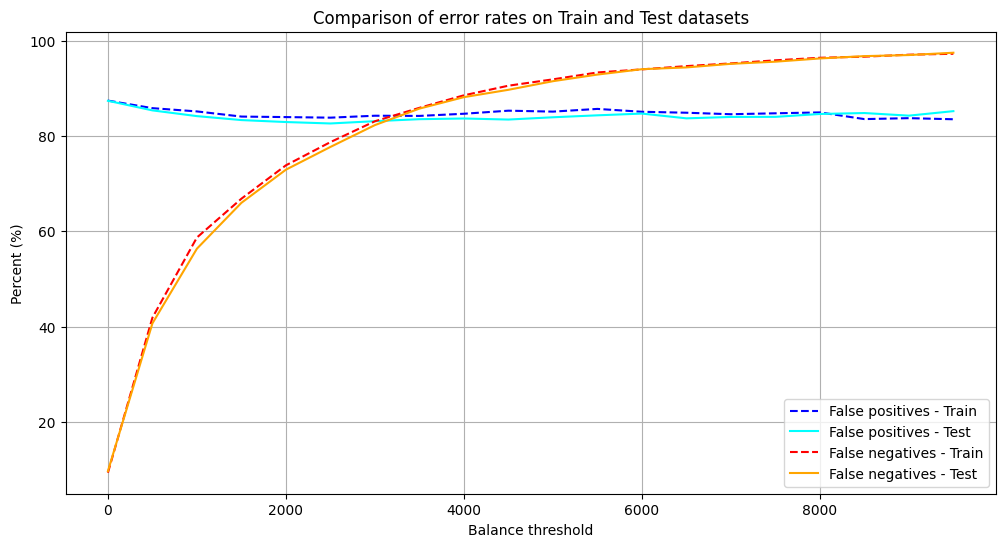

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

thresholds = np.arange(0, 10000, 500)

train_fps = []  # Klienci powyżej progu, którzy nie chcieli lokaty (False Positives %)
test_fps = []
train_fns = []  # Zainteresowani, którzy zostali odrzuceni przez próg (False Negatives %)
test_fns = []

total_train_positives = (train['y'] == 'yes').sum()
total_test_positives = (test['y'] == 'yes').sum()

for t in thresholds:
    # Obliczenia dla zbioru Train
    samples_above_train = train[train['balance'] > t]
    fp_rate_train = (samples_above_train['y'] == 'no').mean() if len(samples_above_train) > 0 else 0
    train_fps.append(fp_rate_train * 100)

    samples_below_train = train[train['balance'] <= t]
    fn_count_train = (samples_below_train['y'] == 'yes').sum()
    train_fns.append((fn_count_train / total_train_positives) * 100)

    # Obliczenia dla zbioru Test
    samples_above_test = test[test['balance'] > t]
    fp_rate_test = (samples_above_test['y'] == 'no').mean() if len(samples_above_test) > 0 else 0
    test_fps.append(fp_rate_test * 100)

    samples_below_test = test[test['balance'] <= t]
    fn_count_test = (samples_below_test['y'] == 'yes').sum()
    test_fns.append((fn_count_test / total_test_positives) * 100)

# Tworzenie wykresu prezentującego wyniki
plt.figure(figsize=(12, 6))
plt.plot(thresholds, train_fps, label='False positives - Train', color='blue', linestyle='--')
plt.plot(thresholds, test_fps, label='False positives - Test', color='cyan')
plt.plot(thresholds, train_fns, label='False negatives - Train', color='red', linestyle='--')
plt.plot(thresholds, test_fns, label='False negatives - Test', color='orange')

plt.xlabel('Balance threshold')
plt.ylabel('Percent (%)')
plt.title('Comparison of error rates on Train and Test datasets')
plt.legend()
plt.grid(True)
plt.show()


Na podstawie wykresu można zauważyć, że wraz ze wzrostem progu salda odsetek false negatives znacząco rośnie, natomiast odsetek false positives pozostaje dosyć stabilny. Dlatego jako kompromis można wybrać próg 2500. Pozwala on ograniczyć liczbę klientów kwalifikowanych do kontaktu, nie zwiększając jeszcze znacząco liczby pominiętych klientów zainteresowanych lokatą.

# Zadanie 3

## 3.0

Znajdź i pobierz zbiór danych CAR EVALUATION z repozytorium danych UCI. Dowiedz się
co opisują pobrane dane.

In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
car_evaluation = fetch_ucirepo(id=19)

# data (as pandas dataframes)
X = car_evaluation.data.features
y = car_evaluation.data.targets

# metadata
print(car_evaluation.metadata)

# variable information
print(car_evaluation.variables)


{'uci_id': 19, 'name': 'Car Evaluation', 'repository_url': 'https://archive.ics.uci.edu/dataset/19/car+evaluation', 'data_url': 'https://archive.ics.uci.edu/static/public/19/data.csv', 'abstract': 'Derived from simple hierarchical decision model, this database may be useful for testing constructive induction and structure discovery methods.', 'area': 'Other', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 1728, 'num_features': 6, 'feature_types': ['Categorical'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1988, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5JP48', 'creators': ['Marko Bohanec'], 'intro_paper': {'ID': 249, 'type': 'NATIVE', 'title': 'Knowledge acquisition and explanation for multi-attribute decision making', 'authors': 'M. Bohanec, V. Rajkovič', 'venue': '8th Intl Workshop on Expert Systems and their Applications, 

## 3.1
Na wykresie tortowym pokaż ile spośród wszystkich samochodów to samochody nieakcepto-
walne, akceptowalne, dobre i bardzo dobre.

  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc


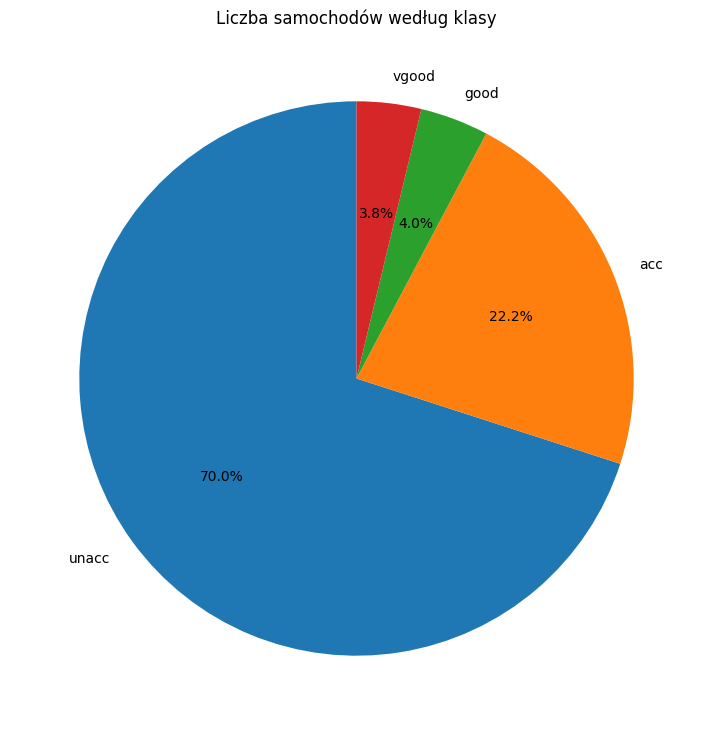

In [ ]:
df = X.join(y)
print(df.head(5))

conditions = df['class'].value_counts()

plt.figure(figsize=(9, 9))
plt.pie(
    conditions.values,
    labels=conditions.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Liczba samochodów według klasy')
plt.show()

## 3.2

Na wykresie słupkowym pokaż ile jest samochodów 2, 3 i 4 drzwiowych w różnych klasach
bezpieczeństwa.

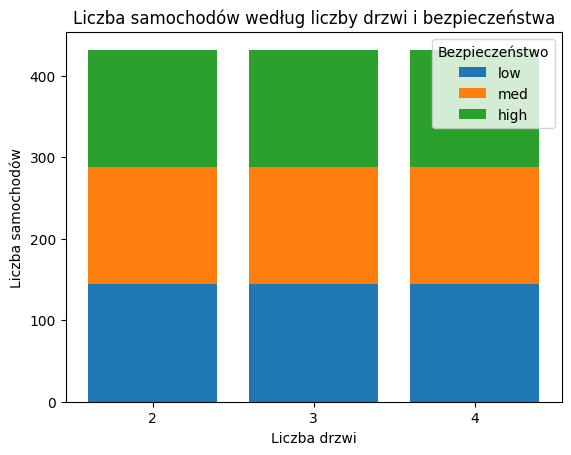

In [ ]:
import matplotlib.pyplot as plt

doors = ["2", "3", "4"]
safety_levels = df['safety'].unique()

bottom = [0] * len(doors)

for safety in safety_levels:
    counts = [
        ((df['doors'] == door) & (df['safety'] == safety)).sum()
        for door in doors
    ]

    plt.bar(doors, counts, bottom=bottom, label=safety)
    bottom = [b + c for b, c in zip(bottom, counts)]


plt.xlabel('Liczba drzwi')
plt.ylabel('Liczba samochodów')
plt.title('Liczba samochodów według liczby drzwi i bezpieczeństwa')
plt.legend(title='Bezpieczeństwo')
plt.show()

## 3.3
Dowiedź się czym jest wykres radarowy (ang. radar plot), nazywany też gwiazdowym lub
pajęczynowym (ang. star plot lub spider plot), i zrób go dla 5 wybranych atrybutów danych.

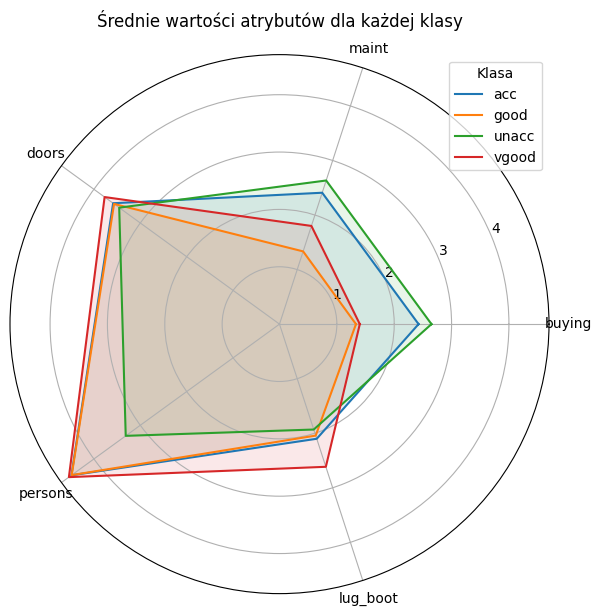

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

features = ['buying', 'maint', 'doors', 'persons', 'lug_boot']

# Zamiana wartości kategorii na liczby
mapping = {
    'buying': {'low': 1, 'med': 2, 'high': 3, 'vhigh': 4},
    'maint': {'low': 1, 'med': 2, 'high': 3, 'vhigh': 4},
    'doors': {'2': 2, '3': 3, '4': 4, '5more': 5},
    'persons': {'2': 2, '4': 4, 'more': 5},
    'lug_boot': {'small': 1, 'med': 2, 'big': 3}
}

data = df.copy()
for col in mapping.keys():
    data[col] = data[col].map(mapping[col])

# Średnie wartości atrybutów dla każdej klasy samochodów
means = data.groupby('class')[features].mean()

# Przygotowanie osi wykresu radarowego
angles = np.linspace(0, 2 * np.pi, len(features), endpoint=False).tolist() # kąty
angles.append(angles[0])

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'polar': True})

for car_class, row in means.iterrows():
    values = row.tolist()
    values.append(values[0])

    ax.plot(angles, values, label=car_class)
    ax.fill(angles, values, alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(features)
ax.legend(title='Klasa')
ax.set_title('Średnie wartości atrybutów dla każdej klasy', pad=20)
plt.show()

## 3.4

Spróbuj określić jakie wartości jakich atrybutów decydują o tym, że samochód jest dobry
lub bardzo dobry. Zrób to intuicyjnie, według własnego pomysłu - w dalszej części wykładu
nauczysz się to robić metodami uczenia maszynowego. Sformułuj regułę, która na podstawie
wartości kilku wybranych atrybutów mówi TAK (dobry lub bardzo dobry) lub NIE. Czy Twoja
reguła działa prawidłowo dla wszystkich danych czy tylko dla części, i jak dużej części? Zrób
rysunek (według własnego pomysłu) pokazujący gdzie reguła robi błędy.

In [ ]:
import matplotlib.pyplot as plt

actual = df['class'].isin(['good', 'vgood'])

predicted = (
    (df['safety'] == 'high') &
    (df['maint'].isin(['low'])) &
    (df['buying'].isin(['low']))
)

correct = (actual == predicted)
print(f"Skuteczność: {round(correct.sum() / len(df), 2) * 100}%")

Skuteczność: 93.0%


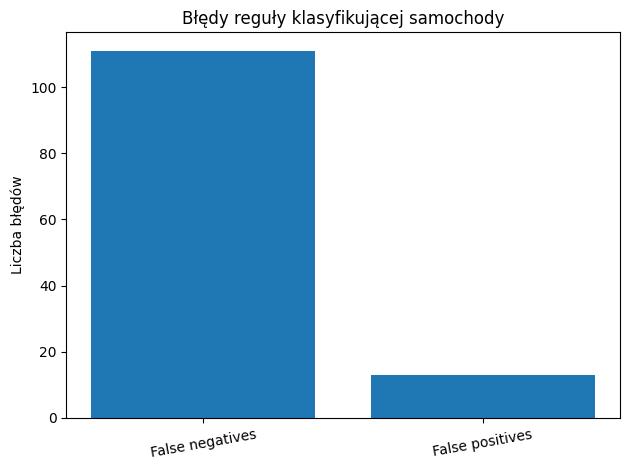

In [ ]:
import matplotlib.pyplot as plt

false_negative = (actual & ~predicted).sum()
false_positive = (~actual & predicted).sum()

labels = [
    'False negatives',
    'False positives'
]
errors = [false_negative, false_positive]

plt.bar(labels, errors)
plt.ylabel('Liczba błędów')
plt.title('Błędy reguły klasyfikującej samochody')
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# Zadanie 4

## 4.0
Przypomnij sobie, albo posłuchaj przypomnienia na wykładzie, czym jest rozkład normalny.



> Rozkład normalny to rozkład prawdopodobieństwa, który ma charakterystyczny kształt dzwonu. Większość obserwacji znajduje się blisko średniej, a im dalej od średniej, tym mniej obserwacji. Ma duże znaczenie w opisnie przyrody oraz zjawisk społecznych.


## 4.1
Wygeneruj milion liczb z rozkładu normalnego o średniej 0 i wariancji 1 używając funkcji
numpy.random.randn(...). Narysuj histogram takich danych.

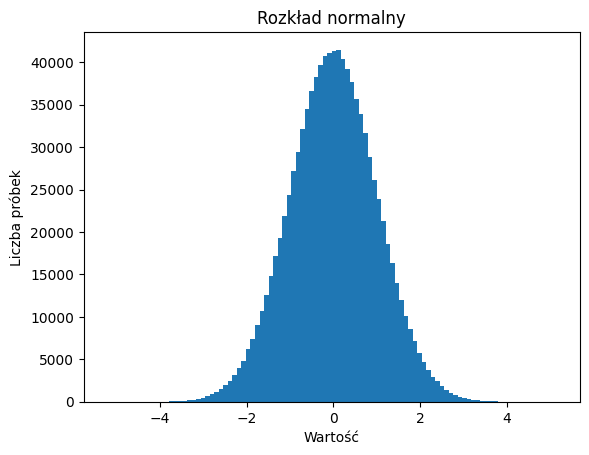

In [ ]:
import numpy as np

numbers = np.random.randn(1_000_000)

plt.hist(numbers, bins=100)
plt.title("Rozkład normalny")
plt.xlabel("Wartość")
plt.ylabel("Liczba próbek")
plt.show()


## 4.2
Na histogramie wygenerowanych danych narysuj funkcję gęstości rozkładu prawdopodobień-
stwa. Porównaj histogram z funkcją gęstości.

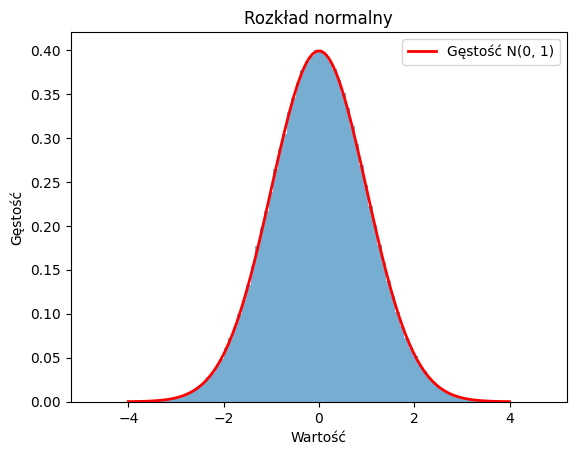

In [ ]:
import numpy as np

numbers = np.random.randn(1_000_000)

x = np.linspace(-4, 4, 100)
y = (1 / np.sqrt(2 * np.pi)) * np.exp(-x**2 / 2)

plt.plot(x, y, 'r', linewidth=2, label='Gęstość N(0, 1)')
plt.hist(numbers, bins=100, density=True, alpha=0.6) # density normalizuje histogram
plt.title("Rozkład normalny")
plt.xlabel("Wartość")
plt.ylabel("Gęstość")
plt.legend()
plt.show()


## 4.3
Przypomnij sobie pkt 3 z Zadania 1. Do atrybutów sepal length i sepal width dodaj za-
burzenie losowe z rozkładem normalnym o średniej 0 i odchyleniu standardowym s = 0.25.

Zobacz jak zmienia się wykres. Czy zaproponowana przez Ciebie reguła odróżniania iris setosa
nadal działa? Spróbuj też użyć innych wartości

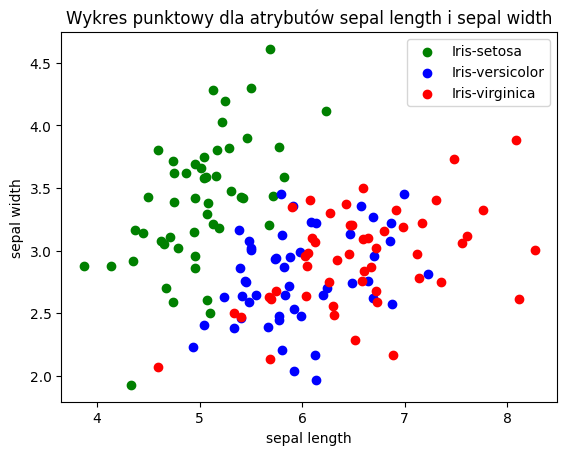

In [ ]:

# fetch dataset
iris = fetch_ucirepo(id=53)

# data (as pandas dataframes)
X = iris.data.features
y = iris.data.targets

df = X.join(y)


species = df['class'].unique()
colors = ['green', 'blue', 'red']

def scatter_plot(a, b):
    """Scatter plot for two attributes"""
    for group, color in zip(species, colors):
        limited_df = df[df['class'] == group] # limit df to a single specie

        plt.scatter(
            limited_df[a] + np.random.normal(0, 0.25, size=len(limited_df)), # do każdej próbki dodajemy zaburzenie
            limited_df[b] + np.random.normal(0, 0.25, size=len(limited_df)),
            c=color,
            label=group
        )

    plt.xlabel(a)
    plt.ylabel(b)
    plt.title(f"Wykres punktowy dla atrybutów {a} i {b}")
    plt.legend()

scatter_plot('sepal length', 'sepal width')

Teraz nie ma już takiej separowalności. Reguła przestaje działać.

# Zadanie 5


## 5.0
Przypomnij sobie, albo posłuchaj przypomnienia na wykładzie, czym jest wielowymiarowy
rozkład normalny.

## 5.1
Wygeneruj milion punktów z dwuwymiarowego rozkładu normalnego o średniej (0, 0) i iden-
tycznościowej macierzy kowariancji używając funkcji numpy.random.randn(...). Narysuj hi-
stogram takich danych (wskazówka: histogram będzie wykresem 3D).

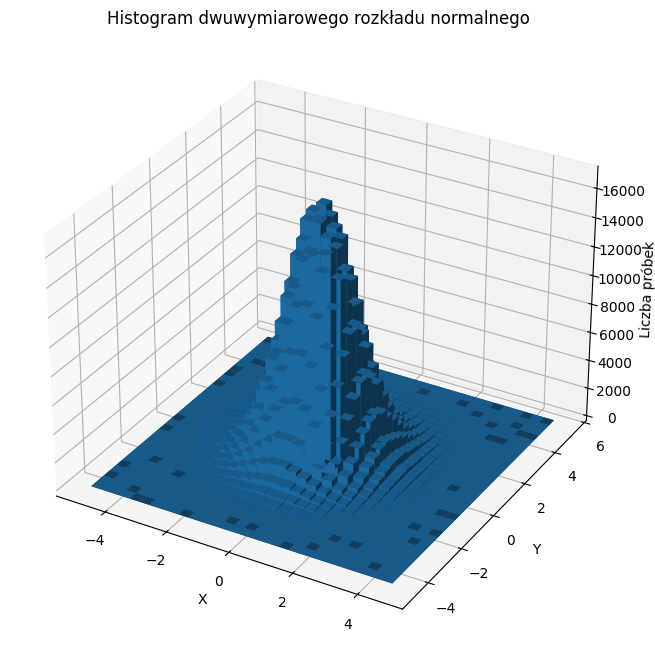

In [ ]:
import numpy as np
from matplotlib import pyplot as plt

data = np.random.randn(1_000_000, 2)
x, y = data[:, 0], data[:, 1]
bins = 30

hist, xedges, yedges = np.histogram2d(x, y, bins=bins)

x, y = np.meshgrid(x_edges[:-1], y_edges[:-1], indexing='ij')

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

ax.bar3d(
    x.ravel(),
    y.ravel(),
    np.zeros(bins*bins), # na początku każdy słupek ma wysokość 0
    x_edges[1] - x_edges[0], # szerokość słupka
    y_edges[1] - y_edges[0],
    hist.ravel() # wysokość słupka
)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Liczba próbek')
ax.set_title('Histogram dwuwymiarowego rozkładu normalnego')
plt.show()

## 5.2

Na histogramie wygenerowanych danych narysuj funkcję gęstości rozkładu prawdopodobień-
stwa (wskazówka: wykres będzie 3D). Porównaj histogram z funkcją gęstości (wskazówka: wy-
godnie będzie zrobić wykres dynamiczny, umożliwiający obracanie i powiększanie, umożliwia

to na przykład pakiet plotly).

In [ ]:

import numpy as np
import plotly.graph_objects as go

data = np.random.randn(1_000_000, 2)
x, y = data[:, 0], data[:, 1]
bins = 30

hist, xedges, yedges = np.histogram2d(x, y, bins=bins)

# Środki przedziałów
xc = (xedges[:-1] + xedges[1:]) / 2
yc = (yedges[:-1] + yedges[1:]) / 2
X, Y = np.meshgrid(xc, yc, indexing='ij')

dx = xedges[1] - xedges[0]
dy = yedges[1] - yedges[0]
density = hist / (len(data) * dx * dy)

Z = (1 / (2 * np.pi)) * np.exp(-(X**2 + Y**2) / 2)

fig = go.Figure()

# Histogram
fig.add_trace(go.Surface(
    x=X, y=Y, z=density,
    name='Histogram',
    colorscale='Blues',
    opacity=0.8
))

# Funkcja gęstości
fig.add_trace(go.Surface(
    x=X, y=Y, z=Z,
    name='Gęstość',
    colorscale='Reds',
    opacity=0.6
))

fig.update_layout(
    title='Histogram a teoretyczna gęstość rozkładu normalnego',
    scene=dict(
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Gęstość prawdopodobieństwa'
    )
)

fig.show()
